# Density-current post-optimization: seeds for the topology sensitivity greedy

Binary seeds for the sequential topology sensitivity (TS) greedy are inferred from the dual solution of the scattered-power bound, with the
RWG current $I$ as the degree of freedom and the non-diagonal material operator $Z_s L$ (as in `maxScatIvecNoChol.ipynb`).
A seed is scored primarily by **its own performance**, the exact scattered power $f_0$ of the binary structure, and secondarily by the power after
the TS greedy started from it. The seed should not depend on the arbitrary parts of the dual solution: the GCD constraint set (global, 10, 20,
40 iterations are compared) and the near-kernel of the Lagrange matrix $L^\star$, which grows with GCD.

**Why the plain co-optimization does not work.** With $g_\mathrm{fit} = \|\tilde I - I(d)\|^2_{L^\star}$ and $g_\mathrm{gap} = \|\tilde I - I^\star\|^2_{L^\star}$,
eliminating $\tilde I$ from any weighted sum gives $w(1-w)\, J(d)$, $J(d) = \|I(d) - I^\star\|^2_{L^\star}$, so every weight transition reduces to the
Lagrangian solution fit (and the $\varepsilon$-continuation of the previous version of this notebook left $d$ unchanged). Residual metrics
$\|W(M(d)\tilde I - DV)\|$ fail for good conductors, as $\|\Lambda^{-1}M\| \sim 10^6$.

**What is done here.**
1. *Log-density.* $d = K^{\bar\rho - 1}$, $\bar\rho \in [0, 1]$, with the contrast $K$ large enough that $\bar\rho = 0$ removes the basis function
   ($|\Lambda_{ii}| \sim 10^{-8}$ against $\|Z'\| \sim 10^{-2}$, so the physical transition of the admittance form lies near $d \sim 10^{-5}$).
2. *Target homotopy (co-optimization).* The target current is moved from the realizable full-plate current to the dual current,
   $\tilde I_t = \arg\min_{\tilde I}\, (1 - t)\|\tilde I - I_\mathrm{full}\|^2_S + t\|\tilde I - I^\star\|^2_S = (1 - t) I_\mathrm{full} + t I^\star$, and the density follows,
   $d_t = \arg\min_d \|I(d) - \tilde I_t\|^2_S$, warm-started from $d_{t - \Delta t}$ (at $t = 0$, $d = 1$ is exact). The proximal variant anchors at
   the current design, $\tilde I_k = \arg\min_{\tilde I}\, \eta\|\tilde I - I^\star\|^2 + (1 - \eta)\|\tilde I - I(d_k)\|^2$ (the alternating
   $g_\mathrm{gap}$/$g_\mathrm{fit}$ weighted sum). The reverse homotopy starts with the direct fit to $I^\star$ from the full plate and
   moves the target back, $t: 1 \to 0$. The direct fit alone (only $t = 1$, followed by the seed extraction) is the control that separates the
   effect of the path from that of the projection refinement.
3. *Metrics $S$.* $L^\star$, the Euclidean norm, and the stored-energy matrix $\omega W$, which penalizes highly reactive currents. $\omega W$ is not available
   for these meshes; it is replaced by $|X_0| = U|\Lambda_X|U^H$ ($X_0 = U\Lambda_X U^H$), which matches $\omega W$ within 1 % on the 285-unknown patch
   mesh where both exist (checked below). Neither $\omega W$ nor the Euclidean norm depends on $L^\star$ and its kernel.
   The *soft-kernel Euclidean* metric comes from augmenting the unknowns by a current $\hat I$,
   $\min_{d, \hat I} \mu_1\|I(d) - \hat I\|^2 + \mu_2\|\hat I - \tilde I_t\|^2_{L^\star}$; eliminating $\hat I$ gives $\|I(d) - \tilde I_t\|^2_S$ with the parallel sum
   $S = \mu_1(\mu_1 + \mu_2 L^\star)^{-1}\mu_2 L^\star$, i.e. the eigenvalues $s_k = \ell_k/(\ell_k + c\,\ell_\mathrm{max})$ (up to a factor) for the eigenvalues
   $\ell_k$ of $L^\star$ and $c\,\ell_\mathrm{max} = \mu_1/\mu_2$: Euclidean for $\ell_k \gg c\,\ell_\mathrm{max}$, and the near-kernel directions, where GCD
   makes $I^\star$ arbitrary, are released. The Euclidean norm can be replaced by another metric $G$, $\min_{d, \hat I} \mu_1\|I(d) - \hat I\|^2_G + \mu_2\|\hat I - \tilde I_t\|^2_{L^\star}$,
   which gives $S = G V \operatorname{diag}(\gamma_k/(\gamma_k + c\,\gamma_\mathrm{max})) V^H G$ with the generalized eigenvalues $L^\star v_k = \gamma_k G v_k$, $V^H G V = 1$;
   $G = \omega W$ (soft-omW) and $G = Z_0^H Z_0$ (soft-Z0HZ0, the error measured by the scattered voltage it produces) are tested.
4. *Density filter.* Averaging over RWG neighbours (sparsity of $L$) regularizes the path, which otherwise hops between binary vertices.
5. *Seed extraction.* Along each path, the binary design with the best exact $f_0$ over thresholds is kept, then refined by a Heaviside projection
   continuation on $f_0$ (the better of the two is the seed).
6. *Portfolio.* The landscape is rugged, so single homotopies are sensitive to the dual. A small deterministic portfolio of homotopies
   (metric, filter, step schedule) is run and the seed with the best exact $f_0$ is selected.

**Additional penalty metric.** The relaxation power $g_\mathrm{relax}(d) = \sum_i |w_i(d)|$, $w_i = \overline{I_i}(V - Z_\mathrm{tot} I)_i = d_i(1-d_i)|u_i|^2/\overline{\Lambda_{ii}}$,
is the pointwise power-conservation violation of the realized relaxed current, zero exactly for binary designs and independent of the multipliers.
For any $d$, $D - J(d) - f_0(I(d)) = \sum_k \lambda_k \operatorname{Re}[p_k^H w(d)]$ (checked below). It is tracked as a diagnostic; with the log-density the
designs become binary by themselves, so it is not needed as a penalty.

In [1]:
import contextlib
import copy
import io
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio
import scipy.sparse as sp
from scipy.linalg import lu_factor, lu_solve
from scipy.optimize import minimize

from dolphindes.cvxopt import DenseSharedProjQCQP, OptimizationHyperparameters
from dolphindes.cvxopt.gcd import GCDHyperparameters

In [2]:
matrixSet = os.environ.get("MATRIX_SET", "patch21ka1") # "patch21ka1" | "dipole": operators loaded from *_{matrixSet}.txt

# Physical constants
epsilon_0 = 8.854e-12 # F/m
mu_0 = 4e-7 * np.pi # H/m
c = 1/np.sqrt(epsilon_0 * mu_0) # speed of light in vacuum

E0 = 1e3 # plane wave amplitude in V/m

frequency = 2.45e9 # frequency in Hz
omega = 2 * np.pi * frequency # angular frequency

copper_conductivity = 5.96e7 # S/m
delta = np.sqrt(2 / (omega * mu_0 * copper_conductivity)) # skin depth in m
Zs = (1 + 1j) / (copper_conductivity * delta) # surface impedance
print(f"Surface impedance: {Zs} Ω")

Surface impedance: (0.012739130327240646+0.012739130327240646j) Ω


In [3]:
def Msym(M):
    return(0.5*(M.conj().T + M))

# Load matrices from text files (original RWG basis, no Cholesky transformation)
Lmat = np.loadtxt(f"Lmat_{matrixSet}.txt", delimiter=',') # lossy matrix
R0 = Msym(np.loadtxt(f"R0_{matrixSet}.txt", delimiter=',')) # radiated power matrix
X0 = Msym(np.loadtxt(f"X0_{matrixSet}.txt", delimiter=',')) # reactive power matrix
Vinc = E0*np.loadtxt(f"V_{matrixSet}.txt", delimiter=',').astype(complex) # voltage excitation vector

Ndes = Lmat.shape[0] # number of design variables
print(f"Matrix set: {matrixSet}, number of design variables: {Ndes}")

Zmat = Zs * Lmat # material impedance matrix (non-diagonal)
Z0 = R0 + 1j*X0 # free-space impedance matrix
Ztot = Z0 + Zmat # total impedance matrix
Ldiag = np.diag(Lmat).copy() # diagonal of the lossy matrix
Lam = Zs*Ldiag # diagonal self-impedance Lambda
Zoff = Ztot - np.diag(Lam) # system matrix without the material self terms, Z'

# stored energy: omega W ~ |X0| (spectral absolute value)
lamX, UX = np.linalg.eigh(X0)
omW = Msym((UX*np.abs(lamX)) @ UX.conj().T)

def evalObj(Ivec):
    # scattered (radiated) power
    return(0.5*np.real(Ivec.conj() @ R0 @ Ivec))

# full plate performance
Ifull = np.linalg.solve(Ztot, Vinc)
Pfull = evalObj(Ifull)
print(f"Objective for full plate: {Pfull:.6e} W, |Lambda_ii| ~ {np.abs(Lam).mean():.2e}, ||Z'||_2 = {np.linalg.norm(Zoff, 2):.2e}")

Matrix set: patch21ka1, number of design variables: 233
Objective for full plate: 4.114174e-02 W, |Lambda_ii| ~ 6.81e-08, ||Z'||_2 = 1.53e-02


In [4]:
# check of the stored-energy proxy on the 285-unknown patch mesh, where omega W is available (maxDQparetoGCD input)
try:
    ref = sio.loadmat("results/maxDQpareto_patch21ka1_gcd20_in.mat")
    Xr, Wr = Msym(ref["X0"]), Msym(ref["omW"])
    lr, Ur = np.linalg.eigh(Xr)
    Xabs = (Ur*np.abs(lr)) @ Ur.T
    rng = np.random.default_rng(0)
    ratios = [np.real(x.conj() @ Wr @ x)/np.real(x.conj() @ Xabs @ x)
              for x in rng.standard_normal((100, Xr.shape[0])) + 1j*rng.standard_normal((100, Xr.shape[0]))]
    print(f"N = {Xr.shape[0]}: ||omW - |X0|||_F / ||omW||_F = {np.linalg.norm(Wr - Xabs)/np.linalg.norm(Wr):.2e}, "
          f"random currents omW/|X0| in [{min(ratios):.4f}, {max(ratios):.4f}]")
except FileNotFoundError:
    print("reference omega W not found, check skipped")

N = 285: ||omW - |X0|||_F / ||omW||_F = 7.16e-03, random currents omW/|X0| in [1.0028, 1.0063]


## QCQP in the current basis and dual solutions

$x = I$, $A_0 = -\tfrac12 R_0$, $A_1 = Z_\mathrm{tot}^H$, $A_2 = 1$, $s_1 = \tfrac12 V$; the projector constraint is $\operatorname{Re}\sum_i p_i^* w_i = 0$ with
$w_i = I_i^*(V - Z_\mathrm{tot} I)_i$. Four dual solutions are computed: the global bound (real and reactive power) and 10, 20, 40 GCD iterations,
each from the global solution. They differ in the bound, in $I^\star$, and in the near-kernel of $L^\star = \operatorname{Sym} A(\lambda^\star)$.

In [5]:
Obj = -0.5 * R0
obj = np.zeros(Ndes, dtype=complex)
obj0 = 0.0
A1 = Ztot.conj().T
s1 = 0.5 * Vinc

def projRes(I, p):
    # Re(-x^H A1 P x + 2 x^H P^H s1) for P = diag(p)
    return(np.real(-I.conj() @ A1 @ (p*I) + 2*I.conj() @ (np.conj(p)*s1)))

opt_params = OptimizationHyperparameters(opttol=1e-6,
    gradConverge=True,
    min_inner_iter=10,
    max_restart=10,
    penalty_ratio=1e-2,
    penalty_reduction=0.1,
    break_iter_period=5,
    verbose=0)

PlistGlob = [sp.diags(q*np.ones(Ndes, dtype=complex)) for q in [1, 1j]] # global real and reactive power
QCQP = DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, PlistGlob, verbose=0)
QCQP.solve_current_dual_problem(method='newton', init_lags=np.array([1.0, 0.0]), opt_params=opt_params)

duals = {"global": QCQP}
for Ngcd in [10, 20, 40]:
    t1 = time.time()
    gQCQP = copy.deepcopy(QCQP)
    gQCQP.verbose = 0
    with contextlib.redirect_stdout(io.StringIO()): # silence the per-iteration GCD output
        gQCQP.run_gcd(GCDHyperparameters(max_proj_cstrt_num=2 + 2*Ngcd, max_gcd_iter_num=Ngcd,
                                         gcd_iter_period=Ngcd + 1, opt_params=opt_params))
    duals[f"GCD {Ngcd}"] = gQCQP
    print(f"GCD {Ngcd}: {time.time()-t1:.1f}s")

dualData = {}
for name, Q in duals.items():
    Lstar = Msym(Q._get_total_A(Q.current_lags))
    ev = np.linalg.eigvalsh(Lstar)
    dualData[name] = dict(D=Q.current_dual, Istar=Q.current_xstar, Lstar=Lstar)
    print(f"{name:7s}: bound {Q.current_dual:.6e} W, eig(L*) in [{ev[0]:.2e}, {ev[-1]:.2e}], "
          f"#(eig < 1e-3 max) = {np.count_nonzero(ev < 1e-3*ev[-1])}, ||I* - I*_global|| / ||I*_global|| = "
          f"{np.linalg.norm(Q.current_xstar - QCQP.current_xstar)/np.linalg.norm(QCQP.current_xstar):.3f}")
print(f"full plate {Pfull:.6e} W")

GCD 10: 7.2s


GCD 20: 27.4s


GCD 40: 106.7s
global : bound 1.847944e+01 W, eig(L*) in [4.63e-08, 4.70e-05], #(eig < 1e-3 max) = 1, ||I* - I*_global|| / ||I*_global|| = 0.000
GCD 10 : bound 1.781534e+01 W, eig(L*) in [4.94e-13, 4.69e-05], #(eig < 1e-3 max) = 45, ||I* - I*_global|| / ||I*_global|| = 0.169
GCD 20 : bound 1.770269e+01 W, eig(L*) in [1.19e-12, 4.69e-05], #(eig < 1e-3 max) = 58, ||I* - I*_global|| / ||I*_global|| = 0.168
GCD 40 : bound 1.757501e+01 W, eig(L*) in [3.31e-14, 4.67e-05], #(eig < 1e-3 max) = 65, ||I* - I*_global|| / ||I*_global|| = 0.179
full plate 4.114174e-02 W


## Design model

$d = K^{\bar\rho - 1}$, the realized current $I(d) = M^{-1}(d)\operatorname{diag}(d) V$ with $M(d) = \Lambda + \operatorname{diag}(d) Z'$, and the exact binary
evaluation (removed basis functions, $Z_{\mathcal A\mathcal A} I_\mathcal A = V_\mathcal A$). The objective of every stage is
$\Phi(\bar\rho) = a_J \|I(d) - \tilde I\|^2_S - a_F f_0(I(d))$ with one adjoint solve for the gradient,
$\partial\Phi/\partial d_j = 2\operatorname{Re}[\overline{\mu_j} u_j]$, $M^H\mu = a_J S(I - \tilde I) - \tfrac12 a_F R_0 I$, $u = V - Z' I$.
The filter is $\bar\rho = H x$ with $H$ the row-normalized adjacency of the RWG functions (nonzeros of $L$), and the projection
$\hat\rho = \frac{\tanh(\beta/2) + \tanh(\beta(\bar\rho - 1/2))}{2\tanh(\beta/2)}$.

In [6]:
kRel = 1e3 # contrast: |Lambda| K = kRel ||Z'||, rho = 0 removes the basis function
K = kRel*np.linalg.norm(Zoff, 2)/np.abs(Lam).min()
lnK = np.log(K)
Aadj = (np.abs(Lmat) > 1e-12*np.abs(Lmat).max()).astype(float)
Hfilt = Aadj/Aadj.sum(1, keepdims=True) # density filter over RWG neighbours
Hnone = np.eye(Ndes)
ths = np.linspace(0.05, 0.95, 19) # thresholds for binarization
print(f"K = {K:.3e}, mean number of RWG neighbours {Aadj.sum(1).mean():.2f}")

def solveD(rb):
    # realized current of the log-density rb
    d = K**(rb - 1)
    lu = lu_factor(np.diag(Lam) + d[:, None]*Zoff)
    I = lu_solve(lu, d*Vinc)
    return d, lu, I, Vinc - Zoff @ I

def exactObj(keep):
    # exact power of the binary structure with the basis functions keep
    keep = np.asarray(keep, dtype=bool)
    if not keep.any():
        return 0.0
    I = np.zeros(Ndes, dtype=complex)
    I[keep] = np.linalg.solve(Ztot[np.ix_(keep, keep)], Vinc[keep])
    return evalObj(I)

def bestThreshold(rb):
    P = [exactObj(rb > t) for t in ths]
    k = int(np.argmax(P))
    return P[k], ths[k]

def relaxW(rb):
    # pointwise power conservation violation w_i = d(1 - d)|u|^2 / conj(Lambda) of the realized relaxed current
    d, _, I, u = solveD(rb)
    return d*(1 - d)*np.abs(u)**2/np.conj(Lam)

def phi(rb, S, It, aJ, aF):
    # aJ ||I(d) - It||_S^2 - aF f0(I(d)) and its gradient w.r.t. rb (one adjoint solve)
    d, lu, I, u = solveD(rb)
    e = I - It
    SE = S @ e if aJ else np.zeros(Ndes, dtype=complex)
    mu = lu_solve(lu, aJ*SE - aF*0.5*(R0 @ I), trans=2)
    return aJ*np.real(np.vdot(e, SE)) - aF*evalObj(I), 2*np.real(np.conj(mu)*u)*d*lnK

def design(x, H, beta=None):
    r = H @ x
    if beta is None:
        return r, np.ones(Ndes)
    den = 2*np.tanh(beta/2)
    th = np.tanh(beta*(r - 0.5))
    return (np.tanh(beta/2) + th)/den, beta*(1 - th**2)/den

def minimizeX(x0, H, S, It, aJ, aF, beta=None, maxiter=2000):
    def fun(x):
        p, dp = design(x, H, beta)
        v, g = phi(p, S, It, aJ, aF)
        return v, H.T @ (dp*g)
    return minimize(fun, x0, jac=True, method='L-BFGS-B', bounds=[(0, 1)]*Ndes,
                    options=dict(maxiter=maxiter, ftol=1e-15, gtol=1e-12, maxcor=30)).x

# checks: relaxed model at a binary design, adjoint gradient, Lagrangian identity of the relaxation power (GCD 20)
rng = np.random.default_rng(0)
keepT = rng.random(Ndes) > 0.4
print(f"binary design: relaxed model {evalObj(solveD(keepT.astype(float))[2]):.6e} W, exact {exactObj(keepT):.6e} W")
rbT, dr = rng.random(Ndes), 1e-6*rng.standard_normal(Ndes)
for args in [(dualData["GCD 20"]["Lstar"], dualData["GCD 20"]["Istar"], 1.0, 0.0), (omW, Ifull, 0.0, 1.0)]:
    print(f"gradient check: FD {(phi(rbT + dr, *args)[0] - phi(rbT - dr, *args)[0])/2:.6e}, adjoint {phi(rbT, *args)[1] @ dr:.6e}")
Q = duals["GCD 20"]
IT = solveD(rbT)[2]
lhs = Q.current_dual - np.real(np.vdot(IT - Q.current_xstar, dualData["GCD 20"]["Lstar"] @ (IT - Q.current_xstar))) - evalObj(IT)
Pcols = Q.Proj.get_Pdata_column_stack()
rhs = sum(l*projRes(IT, Pcols[:, k]) for k, l in enumerate(Q.current_lags))
wT = relaxW(rbT)
print(f"D - J(d) - f0(I(d)) = {lhs:.6e} W, sum_k lambda_k c_k(I(d)) = {rhs:.6e} W, "
      f"sum_k lambda_k Re[p_k^H w] = {sum(l*np.real(np.vdot(Pcols[:, k], wT)) for k, l in enumerate(Q.current_lags)):.6e} W, "
      f"relaxation power {np.sum(np.abs(wT)):.3e} W")

K = 2.247e+08, mean number of RWG neighbours 4.69
binary design: relaxed model 9.825801e-03 W, exact 9.831346e-03 W
gradient check: FD -6.826241e-07, adjoint -6.826242e-07
gradient check: FD 3.744616e-08, adjoint 3.744614e-08
D - J(d) - f0(I(d)) = 2.207616e-01 W, sum_k lambda_k c_k(I(d)) = 2.207603e-01 W, sum_k lambda_k Re[p_k^H w] = 2.207603e-01 W, relaxation power 3.536e-01 W


## Topology sensitivity greedy

Port of `tsGreedy` from `topoOpt.ipynb` (AToM `TS_BF.TSsolver.topoOptGreedy`) to the RWG basis: all single basis function removals and additions are
evaluated exactly by rank-1 updates of $Y = Z_{\mathcal A\mathcal A}^{-1}$, the best one is applied, until no flip increases $f_0$.

In [7]:
def tsGreedy(keep0, maxIt=10**5):
    A = np.flatnonzero(keep0)
    Y = np.linalg.inv(Ztot[np.ix_(A, A)])
    I = Y @ Vinc[A]
    P, nIt = 0.5*np.real(np.vdot(I, R0[np.ix_(A, A)] @ I)), 0
    while nIt < maxIt:
        RAA = R0[np.ix_(A, A)]
        # removal of each active basis function: column k is the current without basis function k
        IBr = I[:, None] - Y*(I/np.diag(Y))[None, :]
        Prem = 0.5*np.real(np.sum(np.conj(IBr)*(RAA @ IBr), axis=0)) if A.size > 1 else np.array([-np.inf])
        # addition of each inactive basis function (Schur complement)
        B = np.setdiff1d(np.arange(Ndes), A)
        if B.size:
            ZAB, ZBA = Ztot[np.ix_(A, B)], Ztot[np.ix_(B, A)]
            X = Y @ ZAB
            s = np.diag(Ztot)[B] - np.sum(ZBA.T*X, axis=0)
            ia = (Vinc[B] - ZBA @ I)/s
            Ia = I[:, None] - X*ia[None, :]
            Padd = 0.5*(np.real(np.sum(np.conj(Ia)*(RAA @ Ia), axis=0))
                        + 2*np.real(ia*np.sum(np.conj(Ia)*R0[np.ix_(A, B)], axis=0))
                        + np.real(np.diag(R0)[B])*np.abs(ia)**2)
        else:
            Padd = np.array([-np.inf])
        kr, ka = np.argmax(Prem), np.argmax(Padd)
        Pnew = max(Prem[kr], Padd[ka])
        if Pnew <= P*(1 + 1e-12):
            break
        if Prem[kr] >= Padd[ka]: # remove A[kr]
            I = np.delete(IBr[:, kr], kr)
            Y = np.delete(np.delete(Y - np.outer(Y[:, kr], Y[kr, :])/Y[kr, kr], kr, 0), kr, 1)
            A = np.delete(A, kr)
        else: # add B[ka], bordered inverse
            b, x, w = B[ka], X[:, ka], ZBA[ka] @ Y
            Y = np.block([[Y + np.outer(x, w)/s[ka], -x[:, None]/s[ka]], [-w[None, :]/s[ka], np.array([[1/s[ka]]])]])
            I = np.append(Ia[:, ka], ia[ka])
            A = np.append(A, b)
            order = np.argsort(A)
            A, I, Y = A[order], I[order], Y[np.ix_(order, order)]
        P, nIt = Pnew, nIt + 1
    keep = np.zeros(Ndes, dtype=bool)
    keep[A] = True
    return keep, P, nIt

keepF, PtsFull, nF = tsGreedy(np.ones(Ndes, dtype=bool))
keepC, PC, _ = tsGreedy(keepT, maxIt=10)
print(f"TS greedy from the full plate: {Pfull:.6e} -> {PtsFull:.6e} W ({nF} flips); "
      f"check: tracked {PC:.10e} W, exact {exactObj(keepC):.10e} W")

TS greedy from the full plate: 4.114174e-02 -> 7.748551e+00 W (63 flips); check: tracked 3.3509870038e+00 W, exact 3.3509870038e+00 W


## Strategies

Each strategy returns its path (designs at the homotopy steps, with the exact $f_0$ of the best thresholded design) and the seed: the best binary
design along the path, or its refinement by the projection continuation $\beta = 1, 2, \dots, 64$ on $\max f_0$, whichever is better.
The baseline is the Lagrangian solution fit $\min J(d)$ in the log-density, started from the full plate ($\varepsilon = 0$ of the previous version).

In [8]:
import scipy.linalg as sla

def softKernel(Lstar, cRel):
    # parallel sum of mu1 1 and mu2 L*, eliminated current hat I: eigenvalues l/(l + c l_max), near-kernel of L* released
    lam, U = np.linalg.eigh(Lstar)
    lam = np.maximum(lam, 0)
    return Msym((U*(lam/(lam + cRel*lam.max()))) @ U.conj().T)

Z0HZ0 = Msym(Z0.conj().T @ Z0)

def softKernelG(Lstar, G, cRel):
    # parallel sum of mu1 G and mu2 L*: G V diag(g/(g + c g_max)) V^H G, L* v = g G v, V^H G V = 1
    g, V = sla.eigh(Lstar, G)
    g = np.maximum(g, 0)
    GV = G @ V
    return Msym((GV*(g/(g + cRel*g.max()))) @ GV.conj().T)

def metric(name, dd):
    if name.startswith("softW"): # "softW <c>": omega W in place of the Euclidean norm
        return softKernelG(dd["Lstar"], omW, float(name.split()[1]))
    if name.startswith("softZ"): # "softZ <c>": Z0^H Z0 in place of the Euclidean norm
        return softKernelG(dd["Lstar"], Z0HZ0, float(name.split()[1]))
    if name.startswith("soft"): # "soft <c>"
        return softKernel(dd["Lstar"], float(name.split()[1]))
    return {"L*": dd["Lstar"], "omW": omW, "Euclid": np.eye(Ndes)}[name]

def pathPoint(t, x, H, S, It):
    rb = H @ x
    P, th = bestThreshold(rb)
    I = solveD(rb)[2]
    return dict(t=t, x=x.copy(), P=P, th=th, Prel=evalObj(I), gfit=np.real(np.vdot(I - It, S @ (I - It))),
                grelax=np.sum(np.abs(relaxW(rb))))

def track(dd, S, H, nT, maxiter):
    # target homotopy: I_t = (1 - t) I_full + t I*, d_t = argmin ||I(d) - I_t||_S, warm-started
    Is = dd["Istar"]
    J0 = np.real(np.vdot(Is - Ifull, S @ (Is - Ifull)))
    x, path = np.ones(Ndes), []
    for t in np.linspace(0, 1, nT + 1)[1:]:
        It = (1 - t)*Ifull + t*Is
        x = minimizeX(x, H, S, It, 1/J0, 0.0, None, maxiter)
        path.append(pathPoint(t, x, H, S, It))
    return path

def trackReverse(dd, S, H, nT, maxiter):
    # reverse target homotopy: direct fit to I* from the full plate, then I_t = (1 - t) I_full + t I*, t: 1 -> 0
    Is = dd["Istar"]
    J0 = np.real(np.vdot(Is - Ifull, S @ (Is - Ifull)))
    x, path = np.ones(Ndes), []
    for t in np.linspace(1, 0, nT + 1)[:-1]:
        It = (1 - t)*Ifull + t*Is
        x = minimizeX(x, H, S, It, 1/J0, 0.0, None, maxiter if t < 1 else 2000)
        path.append(pathPoint(t, x, H, S, It))
    return path

def proximal(dd, S, H, eta, nK):
    # alternating weighted sum: I_k = argmin eta ||I - I*||^2 + (1 - eta) ||I - I(d_k)||^2, d_{k+1} = argmin ||I(d) - I_k||_S
    Is = dd["Istar"]
    J0 = np.real(np.vdot(Is - Ifull, S @ (Is - Ifull)))
    x, path = np.ones(Ndes), []
    for k in range(nK):
        Id = solveD(H @ x)[2]
        It = Id + eta*(Is - Id)
        x = minimizeX(x, H, S, It, 1/J0, 0.0)
        path.append(pathPoint((k + 1)/nK, x, H, S, It))
    return path

def lagFit(dd, S, H):
    # baseline: Lagrangian solution fit min_d ||I(d) - I*||_{L*}, from the full plate
    Is = dd["Istar"]
    x = minimizeX(np.ones(Ndes), H, S, Is, 1/dd["D"], 0.0)
    return [pathPoint(1.0, x, H, S, Is)]

def projectionRefine(x, H, D, betas=(1, 2, 4, 8, 16, 32, 64)):
    best = (-1.0, None)
    for beta in betas:
        x = minimizeX(x, H, None, Ifull, 0.0, 1/D, beta, 300)
        P, th = bestThreshold(design(x, H, beta)[0])
        if P > best[0]:
            best = (P, design(x, H, beta)[0] > th)
    return best

strategies = {
    "L* fit (baseline)":          (lagFit, "L*", Hnone, {}),
    "track omW, filter, 50 steps":  (track, "omW", Hfilt, dict(nT=50, maxiter=20)),
    "track omW, filter, 20 steps":  (track, "omW", Hfilt, dict(nT=20, maxiter=2000)),
    "track Euclid, filter, 50 steps": (track, "Euclid", Hfilt, dict(nT=50, maxiter=20)),
    "track Euclid, filter, 20 steps": (track, "Euclid", Hfilt, dict(nT=20, maxiter=2000)),
    "track L*, 20 steps":           (track, "L*", Hnone, dict(nT=20, maxiter=2000)),
    "track omW, 20 steps":          (track, "omW", Hnone, dict(nT=20, maxiter=2000)),
    "track Euclid, 20 steps":       (track, "Euclid", Hnone, dict(nT=20, maxiter=2000)),
    "proximal omW, eta 0.1":        (proximal, "omW", Hnone, dict(eta=0.1, nK=40)),
    "proximal Euclid, eta 0.1":     (proximal, "Euclid", Hnone, dict(eta=0.1, nK=40)),
    "track soft 1e-3, filter, 50 steps": (track, "soft 1e-3", Hfilt, dict(nT=50, maxiter=20)),
    "track soft 1e-2, filter, 50 steps": (track, "soft 1e-2", Hfilt, dict(nT=50, maxiter=20)),
    "track soft 1e-3, 20 steps":    (track, "soft 1e-3", Hnone, dict(nT=20, maxiter=2000)),
    "track soft 1e-2, 20 steps":    (track, "soft 1e-2", Hnone, dict(nT=20, maxiter=2000)),
    "reverse soft 1e-2, filter, 20 steps": (trackReverse, "soft 1e-2", Hfilt, dict(nT=20, maxiter=2000)),
    "reverse soft 1e-2, filter, 50 steps": (trackReverse, "soft 1e-2", Hfilt, dict(nT=50, maxiter=20)),
    "reverse soft 1e-2, 20 steps":  (trackReverse, "soft 1e-2", Hnone, dict(nT=20, maxiter=2000)),
    "direct soft 1e-2, filter (t = 1 only)": (lagFit, "soft 1e-2", Hfilt, {}),
    "track soft-omW 1e-2, filter, 50 steps": (track, "softW 1e-2", Hfilt, dict(nT=50, maxiter=20)),
    "reverse soft-omW 1e-2, filter, 20 steps": (trackReverse, "softW 1e-2", Hfilt, dict(nT=20, maxiter=2000)),
    "reverse soft-omW 1e-2, filter, 50 steps": (trackReverse, "softW 1e-2", Hfilt, dict(nT=50, maxiter=20)),
    "direct soft-omW 1e-2, filter (t = 1 only)": (lagFit, "softW 1e-2", Hfilt, {}),
    "track soft-Z0HZ0 1e-2, filter, 50 steps": (track, "softZ 1e-2", Hfilt, dict(nT=50, maxiter=20)),
    "reverse soft-Z0HZ0 1e-2, filter, 20 steps": (trackReverse, "softZ 1e-2", Hfilt, dict(nT=20, maxiter=2000)),
    "reverse soft-Z0HZ0 1e-2, filter, 50 steps": (trackReverse, "softZ 1e-2", Hfilt, dict(nT=50, maxiter=20)),
    "direct soft-Z0HZ0 1e-2, filter (t = 1 only)": (lagFit, "softZ 1e-2", Hfilt, {}),
}

def runStrategy(sname, dname):
    fn, mname, H, kw = strategies[sname]
    dd = dualData[dname]
    path = fn(dd, metric(mname, dd), H, **kw)
    kb = int(np.argmax([p["P"] for p in path]))
    P, keep = path[kb]["P"], (H @ path[kb]["x"]) > path[kb]["th"]
    Pp, keepP = projectionRefine(path[kb]["x"], H, dd["D"])
    if Pp > P:
        P, keep = Pp, keepP
    keepTS, PTS, nTS = tsGreedy(keep)
    return dict(path=path, kb=kb, seed=keep, P=P, Ppath=path[kb]["P"], Pproj=Pp, PTS=PTS, nTS=nTS, keepTS=keepTS)

In [9]:
results = {}
t0 = time.time()
for dname in dualData:
    for sname in strategies:
        t1 = time.time()
        r = runStrategy(sname, dname)
        results[(sname, dname)] = r
        print(f"{dname:7s} | {sname:31s}: seed {r['P']:.4e} W (path {r['Ppath']:.3e} at t = {r['path'][r['kb']]['t']:.2f}, "
              f"projection {r['Pproj']:.3e}), {int(r['seed'].sum())}/{Ndes} filled | TS greedy {r['PTS']:.4e} W ({r['nTS']} flips) "
              f"| {time.time()-t1:.1f}s", flush=True)
print(f"all strategies: {time.time()-t0:.0f}s")

global  | L* fit (baseline)              : seed 2.9576e+00 W (path 2.958e+00 at t = 1.00, projection 2.958e+00), 147/233 filled | TS greedy 8.8861e+00 W (28 flips) | 3.1s


global  | track omW, filter, 50 steps    : seed 1.0456e+01 W (path 1.046e+01 at t = 0.22, projection 1.026e+01), 158/233 filled | TS greedy 1.4190e+01 W (29 flips) | 1.8s


global  | track omW, filter, 20 steps    : seed 9.9779e+00 W (path 9.722e+00 at t = 0.50, projection 9.978e+00), 164/233 filled | TS greedy 1.4327e+01 W (35 flips) | 2.1s


global  | track Euclid, filter, 50 steps : seed 1.4737e+01 W (path 1.474e+01 at t = 0.12, projection 1.463e+01), 136/233 filled | TS greedy 1.4812e+01 W (22 flips) | 2.1s


global  | track Euclid, filter, 20 steps : seed 6.2381e+00 W (path 6.238e+00 at t = 0.10, projection 1.859e+00), 79/233 filled | TS greedy 7.3225e+00 W (38 flips) | 4.4s


...

GCD 40  | track soft-Z0HZ0 1e-2, filter, 50 steps: seed 7.2662e+00 W (path 7.266e+00 at t = 0.14, projection 6.665e+00), 74/233 filled | TS greedy 7.3544e+00 W (19 flips) | 2.4s


GCD 40  | reverse soft-Z0HZ0 1e-2, filter, 20 steps: seed 7.2676e+00 W (path 4.711e+00 at t = 1.00, projection 7.268e+00), 141/233 filled | TS greedy 7.6161e+00 W (33 flips) | 4.9s


GCD 40  | reverse soft-Z0HZ0 1e-2, filter, 50 steps: seed 7.0821e+00 W (path 6.490e+00 at t = 0.08, projection 7.082e+00), 120/233 filled | TS greedy 7.3727e+00 W (28 flips) | 2.3s


GCD 40  | direct soft-Z0HZ0 1e-2, filter (t = 1 only): seed 7.7314e+00 W (path 7.144e+00 at t = 1.00, projection 7.731e+00), 140/233 filled | TS greedy 8.0713e+00 W (33 flips) | 1.0s


all strategies: 433s


## Scores

Seed performance (exact $f_0$ of the binary seed) for every strategy and dual solution, the TS greedy result in parentheses. The portfolio seed is
the best seed over the homotopy strategies (the baseline excluded). Robustness is measured by the worst case and the spread over the four dual solutions.

In [10]:
dnames = list(dualData)
snames = list(strategies)
homotopies = [s for s in snames if s != "L* fit (baseline)"]
Pseed = np.array([[results[(s, d)]["P"] for d in dnames] for s in snames])
Pts = np.array([[results[(s, d)]["PTS"] for d in dnames] for s in snames])
portfolio = {d: max(homotopies, key=lambda s: results[(s, d)]["P"]) for d in dnames}

print(f"{'strategy':32s}" + "".join(f"{d:>22s}" for d in dnames) + f"{'worst seed':>12s}{'median':>9s}")
for i, s in enumerate(snames):
    print(f"{s:32s}" + "".join(f"{Pseed[i, j]:9.3f} ({Pts[i, j]:7.3f})   " for j in range(len(dnames)))
          + f"{Pseed[i].min():10.3f}{np.median(Pseed[i]):9.3f}")
Pport = np.array([results[(portfolio[d], d)]["P"] for d in dnames])
PportTS = np.array([results[(portfolio[d], d)]["PTS"] for d in dnames])
print(f"{'portfolio (best seed)':32s}" + "".join(f"{Pport[j]:9.3f} ({PportTS[j]:7.3f})   " for j in range(len(dnames)))
      + f"{Pport.min():10.3f}{np.median(Pport):9.3f}")
print(f"{'bound':32s}" + "".join(f"{dualData[d]['D']:9.3f}             " for d in dnames))
print(f"full plate {Pfull:.4f} W, TS greedy from the full plate {PtsFull:.4f} W")
for d in dnames:
    print(f"{d:7s}: portfolio seed from '{portfolio[d]}'")

# agreement of the portfolio seeds across the dual solutions (Hamming distance, number of basis functions)
seeds = [results[(portfolio[d], d)]["seed"] for d in dnames]
print("Hamming distances of the portfolio seeds:\n" + "\n".join(
    f"{d:7s} " + " ".join(f"{np.count_nonzero(seeds[i] != seeds[j]):4d}" for j in range(len(dnames))) for i, d in enumerate(dnames)))

# results without the optimization variables, to redraw the figures without rerunning GCD
import pickle
with open(f"results/postOpt_results_{matrixSet}.pkl", "wb") as fh:
    pickle.dump(dict(results={k: {kk: (vv if kk != "path" else [{q: p[q] for q in p if q != "x"} for p in vv])
                                  for kk, vv in r.items()} for k, r in results.items()},
                     dualData={d: dict(D=dd["D"], Istar=dd["Istar"]) for d, dd in dualData.items()},
                     Pfull=Pfull, PtsFull=PtsFull), fh)

strategy                                        global                GCD 10                GCD 20                GCD 40  worst seed   median
L* fit (baseline)                   2.958 (  8.886)       8.985 (  9.120)       8.949 (  8.993)       0.027 (  8.280)        0.027    5.953
track omW, filter, 50 steps        10.456 ( 14.190)      14.867 ( 15.038)       9.741 ( 15.036)      13.538 ( 15.073)        9.741   11.997
track omW, filter, 20 steps         9.978 ( 14.327)      12.569 ( 14.742)       5.224 (  6.513)       5.949 (  6.140)        5.224    7.963
track Euclid, filter, 50 steps     14.737 ( 14.812)      13.470 ( 14.813)      14.324 ( 15.043)       5.146 (  5.750)        5.146   13.897
track Euclid, filter, 20 steps      6.238 (  7.322)       9.067 ( 14.990)       2.250 (  5.499)       3.833 (  6.850)        2.250    5.035
track L*, 20 steps                 13.454 ( 14.817)      14.194 ( 14.845)      13.693 ( 14.885)      11.979 ( 14.555)       11.979   13.573
track omW, 20 step

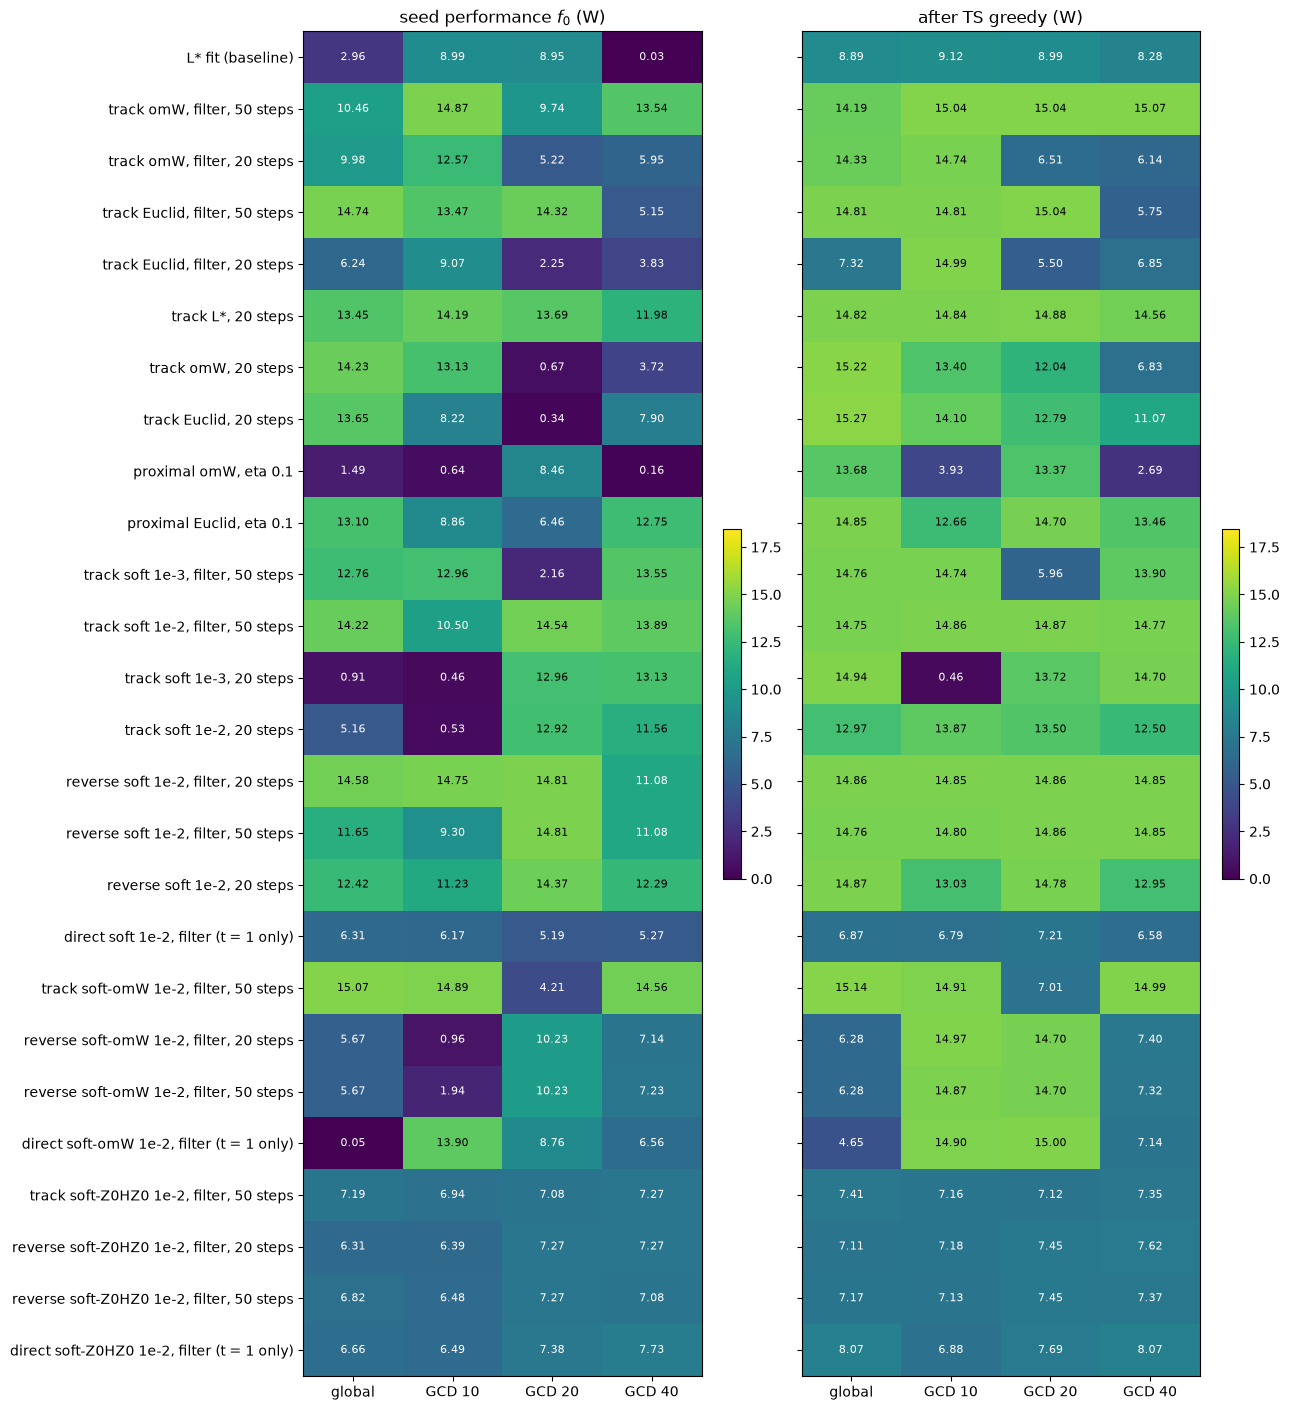

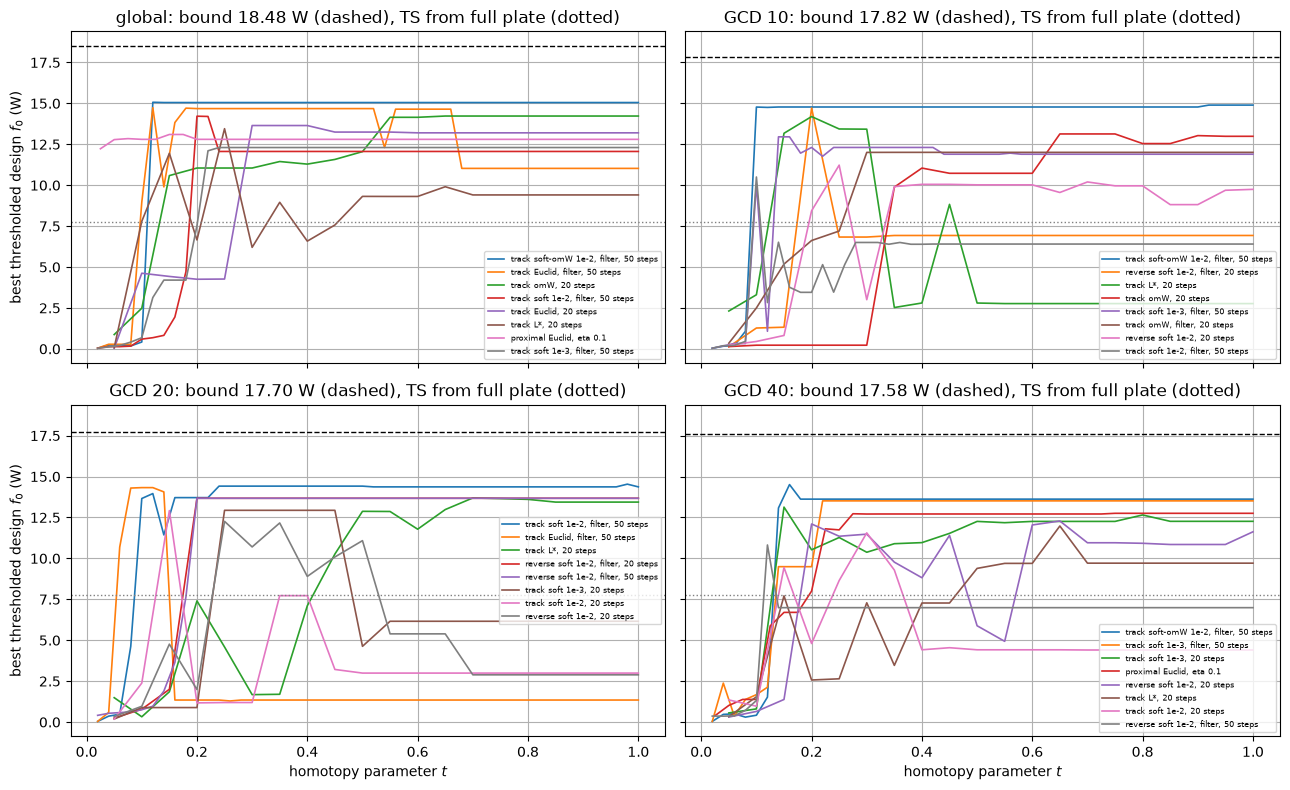

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 0.45*len(snames) + 2.5), sharey=True)
for ax, data, title in [(axes[0], Pseed, 'seed performance $f_0$ (W)'), (axes[1], Pts, 'after TS greedy (W)')]:
    im = ax.imshow(data, cmap='viridis', aspect='auto', vmin=0, vmax=max(d['D'] for d in dualData.values()))
    for i in range(len(snames)):
        for j in range(len(dnames)):
            ax.text(j, i, f"{data[i, j]:.2f}", ha='center', va='center', fontsize=8,
                    color='k' if data[i, j] > 0.6*im.get_clim()[1] else 'w')
    ax.set_xticks(range(len(dnames)), dnames)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.04)
axes[0].set_yticks(range(len(snames)), snames)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey=True)
for ax, d in zip(axes.ravel(), dnames):
    top = sorted(homotopies, key=lambda s: -max(p["P"] for p in results[(s, d)]["path"]))[:8] # 8 best paths
    for s in top:
        path = results[(s, d)]["path"]
        ax.plot([p["t"] for p in path], [p["P"] for p in path], '-', lw=1.2, label=s)
    ax.axhline(dualData[d]["D"], ls='--', c='k', lw=1)
    ax.axhline(PtsFull, ls=':', c='gray', lw=1)
    ax.set_title(f"{d}: bound {dualData[d]['D']:.2f} W (dashed), TS from full plate (dotted)")
    ax.grid(True)
for ax in axes[1]:
    ax.set_xlabel('homotopy parameter $t$')
for ax in axes[:, 0]:
    ax.set_ylabel('best thresholded design $f_0$ (W)')
for ax in axes.ravel():
    ax.legend(fontsize=6)
plt.tight_layout(); plt.show()

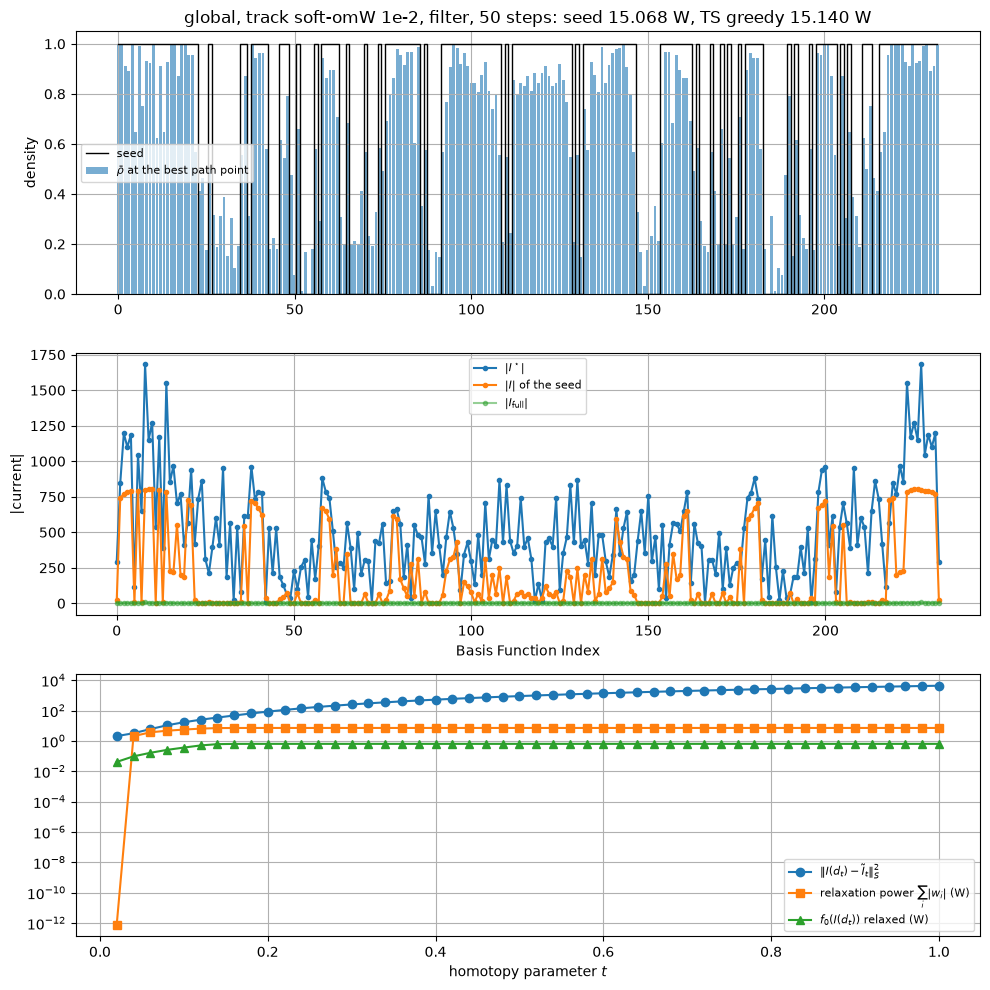

In [12]:
dBest = max(dnames, key=lambda d: results[(portfolio[d], d)]["P"])
rB = results[(portfolio[dBest], dBest)]
pB = rB["path"][rB["kb"]]
Hs = strategies[portfolio[dBest]][2]
IseedB = np.zeros(Ndes, dtype=complex)
IseedB[rB["seed"]] = np.linalg.solve(Ztot[np.ix_(rB["seed"], rB["seed"])], Vinc[rB["seed"]])

fig, axes = plt.subplots(3, 1, figsize=(10, 10))
axes[0].bar(np.arange(Ndes), Hs @ pB["x"], alpha=0.6, label=r'$\bar\rho$ at the best path point')
axes[0].step(np.arange(Ndes), rB["seed"].astype(float), where='mid', c='k', lw=1, label='seed')
axes[0].set_title(f"{dBest}, {portfolio[dBest]}: seed {rB['P']:.3f} W, TS greedy {rB['PTS']:.3f} W")
axes[0].set_ylabel('density'); axes[0].legend(fontsize=8); axes[0].grid(True)
axes[1].plot(np.abs(dualData[dBest]["Istar"]), '.-', label=r'$|I^\star|$')
axes[1].plot(np.abs(IseedB), '.-', label=r'$|I|$ of the seed')
axes[1].plot(np.abs(Ifull), '.-', alpha=0.5, label=r'$|I_\mathrm{full}|$')
axes[1].set_ylabel('|current|'); axes[1].legend(fontsize=8); axes[1].grid(True)
path = rB["path"]
axes[2].semilogy([p["t"] for p in path], [p["gfit"] for p in path], 'o-', label=r'$\|I(d_t) - \tilde I_t\|^2_S$')
axes[2].semilogy([p["t"] for p in path], [p["grelax"] for p in path], 's-', label=r'relaxation power $\sum_i |w_i|$ (W)')
axes[2].semilogy([p["t"] for p in path], [p["Prel"] for p in path], '^-', label=r'$f_0(I(d_t))$ relaxed (W)')
axes[2].set_xlabel('homotopy parameter $t$'); axes[2].legend(fontsize=8); axes[2].grid(True)
axes[1].set_xlabel('Basis Function Index')
plt.tight_layout(); plt.show()

## Best seed designs and their currents

The four best seeds over all strategies and dual solutions (distinct designs) on the mesh of `exportOmWpatch21ka1.m` (`mesh_patch21ka1.mat`).
A removed basis function cuts its edge (black line, no current across it). The surface current density is evaluated at the triangle centroids,
$\boldsymbol J = \sum_n I_n \boldsymbol f_n$ with $\boldsymbol f_n = \pm(\boldsymbol r - \boldsymbol p_n^\pm)/(2A^\pm)$; the color is $|\boldsymbol J|$ and the arrows show
$\operatorname{Re}(\boldsymbol J\, e^{-j\varphi})$ at the phase $\varphi$ of largest real part. Each seed current is shown next to the dual current $I^\star$ of the dual
solution it was inferred from. The seeds are saved to `results/postOpt_seeds_{matrixSet}.npz`.

global  | track soft-omW 1e-2, filter, 50 steps: seed 15.0680 W, TS greedy 15.1403 W
GCD 10  | track soft-omW 1e-2, filter, 50 steps: seed 14.8950 W, TS greedy 14.9122 W
GCD 10  | track omW, filter, 50 steps: seed 14.8673 W, TS greedy 15.0385 W
GCD 20  | reverse soft 1e-2, filter, 20 steps: seed 14.8088 W, TS greedy 14.8574 W


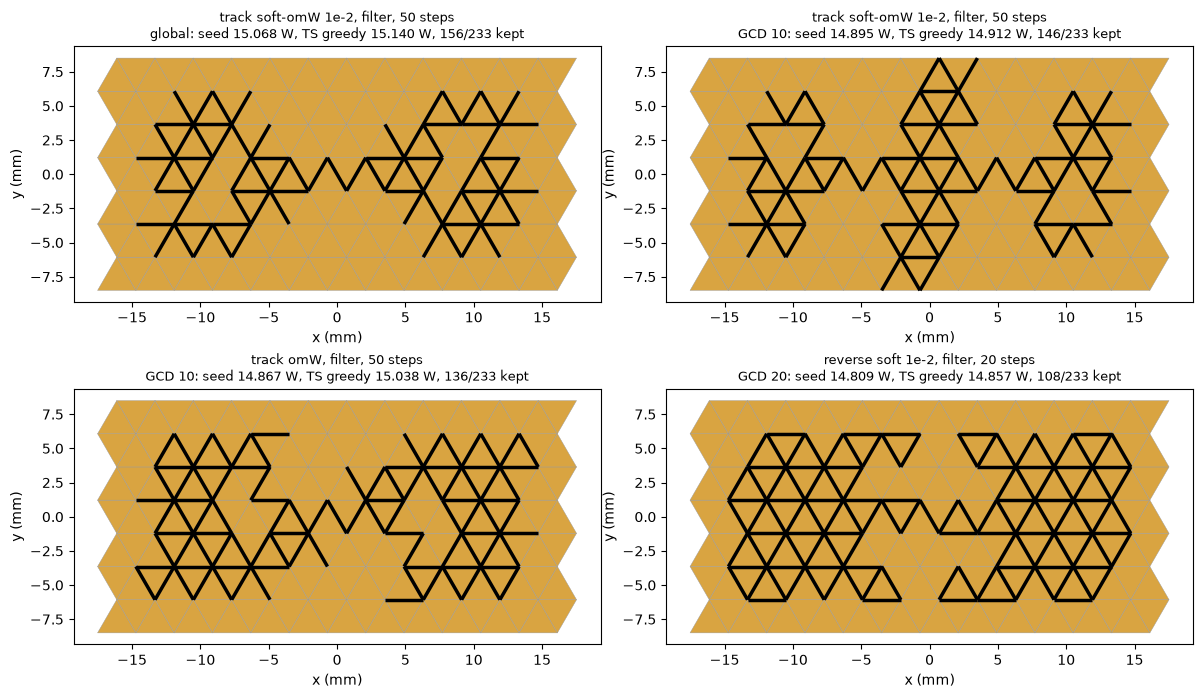

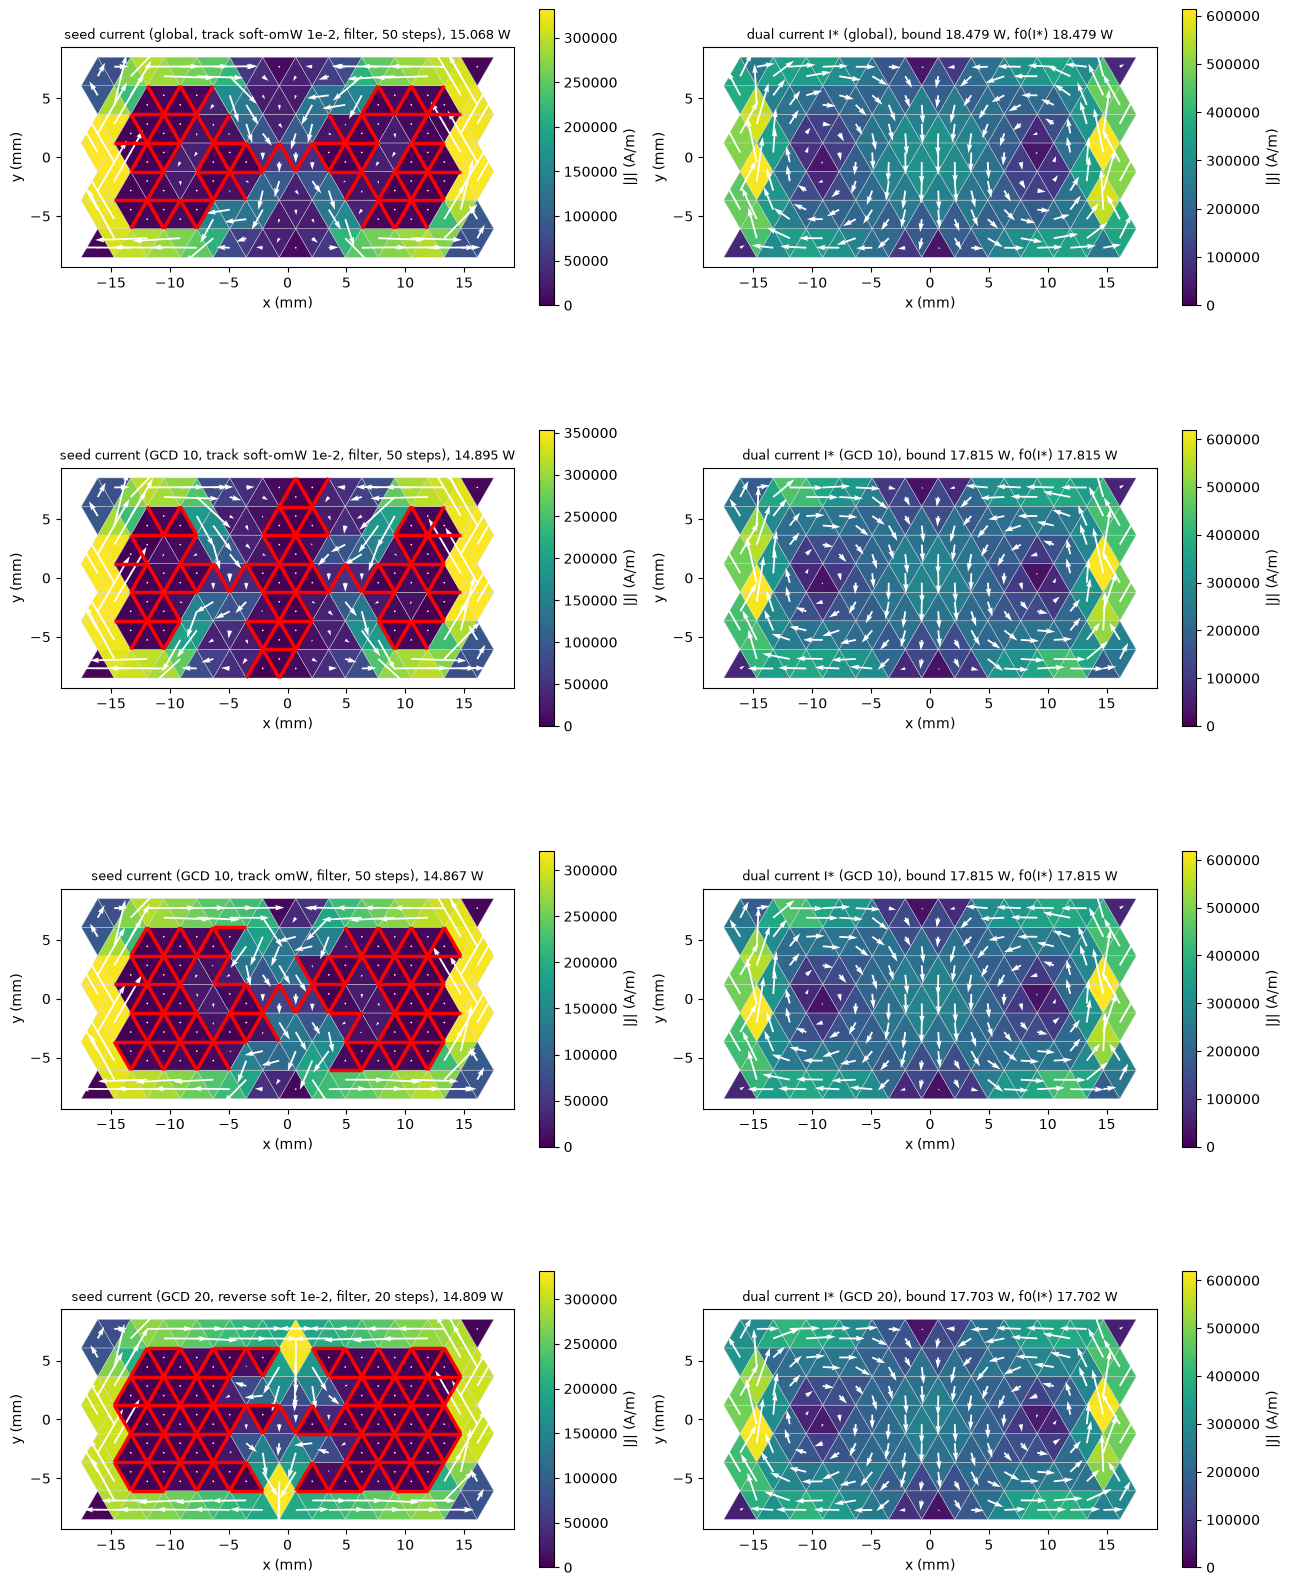

In [13]:
from matplotlib.collections import LineCollection, PolyCollection

ranked = sorted(results, key=lambda k: -results[k]["P"])
best4 = []
for key in ranked: # four distinct seeds with the largest scattered power
    if all(np.any(results[key]["seed"] != results[k]["seed"]) for k in best4):
        best4.append(key)
    if len(best4) == 4:
        break
np.savez(f"results/postOpt_seeds_{matrixSet}.npz", seeds=np.array([results[k]["seed"] for k in best4]),
         P=np.array([results[k]["P"] for k in best4]), PTS=np.array([results[k]["PTS"] for k in best4]),
         labels=np.array([f"{s} | {d}" for s, d in best4]))
for s, d in best4:
    print(f"{d:7s} | {s}: seed {results[(s, d)]['P']:.4f} W, TS greedy {results[(s, d)]['PTS']:.4f} W")

def seedCurrent(keep):
    I = np.zeros(Ndes, dtype=complex)
    I[keep] = np.linalg.solve(Ztot[np.ix_(keep, keep)], Vinc[keep])
    return I

meshFile = f"mesh_{matrixSet}.mat"
if os.path.exists(meshFile):
    msh = sio.loadmat(meshFile)
    nodes, tris, bfm = msh["nodes"]*1e3, msh["triangles"].astype(int), msh["bf"].astype(int) # nodes in mm
    e1v, e2v = nodes[tris[:, 1]] - nodes[tris[:, 0]], nodes[tris[:, 2]] - nodes[tris[:, 0]]
    area = 0.5*np.abs(e1v[:, 0]*e2v[:, 1] - e1v[:, 1]*e2v[:, 0])*1e-6 # m^2
    cen = nodes[tris].mean(axis=1)
    free = np.array([[[v for v in tris[t] if v not in (e1, e2)][0] for t in (tp, tm)] for tp, tm, e1, e2 in bfm])

    def triangleCurrent(I):
        # surface current density (A/m) at the triangle centroids
        J = np.zeros((len(tris), 2), dtype=complex)
        for n, (tp, tm, e1, e2) in enumerate(bfm):
            J[tp] += I[n]*(cen[tp] - nodes[free[n, 0]])*1e-3/(2*area[tp])
            J[tm] += I[n]*(nodes[free[n, 1]] - cen[tm])*1e-3/(2*area[tm])
        return J

    def plotCurrent(ax, I, keep, title, vmax=None):
        J = triangleCurrent(I)
        Jabs = np.sqrt(np.sum(np.abs(J)**2, axis=1))
        pc = PolyCollection(nodes[tris], array=Jabs, cmap='viridis', edgecolors='0.85', linewidths=0.3)
        pc.set_clim(0, vmax if vmax is not None else Jabs.max())
        ax.add_collection(pc)
        phi = 0.5*np.angle(np.sum(J*J)) # phase of the largest real part
        Jr = np.real(J*np.exp(-1j*phi))
        ax.quiver(cen[:, 0], cen[:, 1], Jr[:, 0], Jr[:, 1], color='w', scale=None, width=0.004)
        if keep is not None:
            ax.add_collection(LineCollection(nodes[bfm[~keep][:, 2:]], colors='r', linewidths=2.5))
        ax.autoscale(); ax.set_aspect('equal')
        ax.set_title(title, fontsize=9)
        ax.set_xlabel('x (mm)'); ax.set_ylabel('y (mm)')
        plt.colorbar(pc, ax=ax, fraction=0.03, label='|J| (A/m)')

    # structures
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    for ax, (s, d) in zip(axes.ravel(), best4):
        r = results[(s, d)]
        ax.add_collection(PolyCollection(nodes[tris], facecolors='#d9a441', edgecolors='0.6', linewidths=0.3))
        ax.add_collection(LineCollection(nodes[bfm[~r['seed']][:, 2:]], colors='k', linewidths=2.5))
        ax.autoscale(); ax.set_aspect('equal')
        ax.set_title(f"{s}\n{d}: seed {r['P']:.3f} W, TS greedy {r['PTS']:.3f} W, {r['seed'].sum()}/{Ndes} kept", fontsize=9)
        ax.set_xlabel('x (mm)'); ax.set_ylabel('y (mm)')
    plt.tight_layout(); plt.show()

    # currents: seed (left) and dual current of the same dual solution (right)
    fig, axes = plt.subplots(4, 2, figsize=(13, 17))
    for row, (s, d) in zip(axes, best4):
        r = results[(s, d)]
        plotCurrent(row[0], seedCurrent(r['seed']), r['seed'], f"seed current ({d}, {s}), {r['P']:.3f} W")
        Is = dualData[d]["Istar"]
        plotCurrent(row[1], Is, None, f"dual current I* ({d}), bound {dualData[d]['D']:.3f} W, f0(I*) {evalObj(Is):.3f} W")
    plt.tight_layout(); plt.show()
else:
    print(f"{meshFile} not found, plot skipped")

## Observations (patch21ka1, 233 unknowns)

* **GCD is not reproducible.** Between runs of this notebook the GCD bounds change in the third to fourth digit (GCD 10: 17.78 to 17.83 W),
  and single-strategy seeds change by up to 14 W, which illustrates the sensitivity to the dual solution that the seeds should not inherit.
* **Baseline.** The Lagrangian solution fit gives seeds of 3.0 to 9.0 W, and 8.9 to 9.2 W after the TS greedy. The TS greedy from the full plate
  reaches 7.75 W.
* **Portfolio.** The best seed reaches 14.47 to 15.07 W for all four dual solutions (81 to 85 % of the respective bound) and 14.9 to 15.1 W after the
  TS greedy, which adds at most 0.6 W: the seeds are close to TS local optima. The portfolio seeds differ in 42 to 85 basis functions between the
  dual solutions but perform alike, i.e. there are several nearly equivalent designs. Across the last three runs, the portfolio always stayed
  between 14.4 and 15.1 W.
* **Single strategies.** Every single strategy failed for some dual solution in at least one run. The forward soft-kernel homotopy (Euclidean,
  $c = 10^{-2}$, averaging, 50 steps) was the most robust over three runs (worst 13.0, 14.2, 10.2 W, median 14.3 to 14.4 W). The reverse
  homotopy (20 steps) reached a worst case of 14.5 W in a test, but 9.7 and 5.9 W in two notebook runs.
* **Soft-kernel metric with $G = \omega W$.** It gives the best single seed (15.07 W, global) but fails for GCD 10 (0.09 W), so it is not robust.
* **Soft-kernel metric with $G = Z_0^H Z_0$.** It is very consistent (6.3 to 7.4 W for all variants and dual solutions) but converges to a poor
  basin: the seeds stay at the level of the TS greedy from the full plate. Since $Z_0^H Z_0 \approx |X_0|^2$ for the dominant
  reactive part, it weights highly reactive error components quadratically instead of linearly as $\omega W$, and the fit is dominated by them.
* **Direct fit at $t = 1$** (control, followed by the projection refinement): 0.1 to 6.3 W for the Euclidean soft-kernel metric, so the path, not
  only the projection, produces the good seeds.
* **Path.** The seed performance jumps at $t \approx 0.1$ to $0.3$ and is mostly flat or decreasing afterwards: the dual current acts as a direction
  away from the full plate, and fitting it completely ($t = 1$) is not needed.
* **Relaxation power.** It vanishes only at the full plate ($t \to 0$); with the log-density the thresholded designs are binary-exact anyway, so it is
  a diagnostic of the relaxed path, not a needed penalty.
* **Dipole** (`MATRIX_SET=dipole`, earlier run): every strategy returns the full plate (10.108 W), a TS local optimum within 0.002 % of the
  GCD-40 bound.